In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import time as py_time
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from tinkoff.invest import Client, CandleInterval, RequestError
from tinkoff.invest.utils import now, quotation_to_decimal

TINKOFF_API_TOKEN = "t.He-UEc5Mfe_E2w9CVSlZsCrqyoFacn52Yut_rwdsK8EclvfaxLlju33-26Z2cW22w0dDKNK0cNpxsyXLSGZv-g"

INSTRUMENT_FIGI = "BBG004730N88"
DAYS_HISTORY = 1
CANDLE_TIMEFRAME = CandleInterval.CANDLE_INTERVAL_1_MIN
N_STEPS_IN = 814
N_STEPS_OUT = 60
FEATURE_COLUMN = 'close'

2025-05-10 18:25:11.621508: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-10 18:25:11.640605: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-10 18:25:11.652525: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1746890711.669387 1333870 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1746890711.674736 1333870 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1746890711.698901 1333870 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linkin

In [2]:
def get_tinkoff_candles(token, figi, days, interval):
    with Client(token) as client:
        end_dt = now()
        start_dt = end_dt - timedelta(days=days)
        candles = list(client.get_all_candles(figi=figi, from_=start_dt, to=end_dt, interval=interval))
        df = pd.DataFrame([{ 'time': pd.Timestamp(c.time).tz_localize(None),
                             'open': float(quotation_to_decimal(c.open)),
                             'high': float(quotation_to_decimal(c.high)),
                             'low': float(quotation_to_decimal(c.low)),
                             'close': float(quotation_to_decimal(c.close)),
                             'volume': c.volume } for c in candles])
        df = df.set_index('time').sort_index().dropna()
        print("Исходные данные (первые и последние 5 строк):")
        print(pd.concat([df.head(), df.tail()]))
        return df

In [17]:
def prepare_data(df, feature_col):
    values = df[[feature_col]].dropna().values.astype(float)
    return values, df[feature_col]


In [4]:
def split_sequences(data, n_steps_in, n_steps_out):
    X, y = [], []
    for i in range(len(data) - n_steps_in - n_steps_out + 1):
        X.append(data[i:i+n_steps_in])
        y.append(data[i+n_steps_in:i+n_steps_in+n_steps_out])
    return np.array(X), np.array(y)

In [5]:
def build_lstm_model(n_steps_in, n_steps_out):
    model = Sequential()
    model.add(LSTM(75, return_sequences=True, input_shape=(n_steps_in, 1)))
    model.add(Dropout(0.2))
    model.add(LSTM(75))
    model.add(Dropout(0.2))
    model.add(Dense(50, activation='relu'))
    model.add(Dense(n_steps_out))
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

In [6]:
def plot_predictions(dates, actual, predicted, title):
    plt.figure(figsize=(12, 4))
    plt.plot(dates, actual, label='Actual')
    plt.plot(dates, predicted, label='Predicted')
    plt.title(title)
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [8]:
def cross_validate_lstm(X, y, scaler, n_splits=4):
    best_mse = float('inf')
    best_model = None
    best_history = None

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for fold, (train_idx, val_idx) in enumerate(kf.split(X)):
        print(f"--- Обучение модели fold {fold+1} ---")
        model = build_lstm_model(N_STEPS_IN, N_STEPS_OUT)

        X_train, y_train = X[train_idx], y[train_idx]
        X_val, y_val = X[val_idx], y[val_idx]

        history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=50, batch_size=32, verbose=0,
                            callbacks=[EarlyStopping(monitor='val_loss', patience=5)])

        preds = model.predict(X_val)
        preds_inv = scaler.inverse_transform(preds.squeeze())
        y_val_inv = scaler.inverse_transform(y_val.squeeze())


        mse = mean_squared_error(y_val_inv[:, 0], preds_inv[:, 0])
        print(f"MSE fold {fold+1}: {mse:.6f}")

        print("\nСравнение фактических и предсказанных значений:")
        for i in range(len(y_val_inv)):
            print(f"{i}: Факт = {y_val_inv[i][0]:.4f}, Прогноз = {preds_inv[i][0]:.4f}")

        time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')
        plot_predictions(time_indexes, y_val_inv[:, 0], preds_inv[:, 0], title=f"Fold {fold+1} Prediction")

        if mse < best_mse:
            best_mse = mse
            best_model = model
            best_history = history

    print(f"\nВыбрана лучшая модель с MSE: {best_mse:.6f}")
    return best_model

In [15]:
def final_test(model, X_test, y_test, scaler, original_df, window_size):
    preds = model.predict(X_test)

    # Используем только первое значение прогноза (например, следующий момент)
    y_test_1step = y_test[:, 0]
    preds_1step = preds[:, 0]

    y_test_2d = y_test_1step.reshape(-1, 1)
    preds_2d = preds_1step.reshape(-1, 1)

    y_test_inv = scaler.inverse_transform(y_test_2d)
    preds_inv = scaler.inverse_transform(preds_2d)

    dates = original_df.index[-len(y_test):][:len(y_test_inv)]

    result_df = pd.DataFrame({
        'datetime': dates,
        'actual_close': y_test_inv.flatten(),
        'predicted_close': preds_inv.flatten()
    }).set_index('datetime')

    print("Сравнение фактических и предсказанных значений:")
    print(result_df)

    plt.figure(figsize=(15, 6))
    plt.plot(result_df.index, result_df['actual_close'], label='Фактическая цена')
    plt.plot(result_df.index, result_df['predicted_close'], label='Прогноз', linestyle='--')
    plt.title("Фактическая и предсказанная цена закрытия")
    plt.xlabel("Дата и время")
    plt.ylabel("Цена")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    mse = mean_squared_error(y_test_inv, preds_inv)
    print(f"\nСреднеквадратичная ошибка (MSE): {mse:.6f}")


Исходные данные (первые и последние 5 строк):
                       open    high     low   close  volume
time                                                       
2025-05-09 16:26:00  303.90  303.90  303.90  303.90       1
2025-05-09 16:27:00  303.90  303.90  303.90  303.90       1
2025-05-09 16:28:00  303.66  303.66  303.66  303.66       2
2025-05-09 16:29:00  303.65  303.93  303.65  303.93       8
2025-05-09 16:30:00  303.66  303.93  303.65  303.93      66
2025-05-10 16:21:00  302.71  302.71  302.71  302.71       1
2025-05-10 16:22:00  302.70  302.70  302.35  302.35       2
2025-05-10 16:23:00  302.60  302.71  302.60  302.70       9
2025-05-10 16:24:00  302.70  302.70  302.36  302.70       9
2025-05-10 16:25:00  302.70  302.70  302.70  302.70       5
--- Обучение модели fold 1 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step
MSE fold 1: 0.009438

Сравнение фактических и предсказанных значений:
0: Факт = 303.0800, Прогноз = 303.0577
1: Факт = 303.0000, Прогноз = 303.0338
2: Факт = 303.1000, Прогноз = 303.0690
3: Факт = 303.0700, Прогноз = 303.0475
4: Факт = 303.0900, Прогноз = 303.0701
5: Факт = 302.8400, Прогноз = 302.9868
6: Факт = 303.0400, Прогноз = 303.0630
7: Факт = 303.1800, Прогноз = 303.0614
8: Факт = 303.0800, Прогноз = 303.0501
9: Факт = 303.0100, Прогноз = 303.0705
10: Факт = 302.8300, Прогноз = 302.9888
11: Факт = 303.2800, Прогноз = 302.9862
12: Факт = 303.0900, Прогноз = 303.0669
13: Факт = 303.0900, Прогноз = 303.0587
14: Факт = 303.0300, Прогноз = 303.0323
15: Факт = 302.9700, Прогноз = 303.0501
16: Факт = 303.0300, Прогноз = 303.0327
17: Факт = 302.9100, Прогноз = 302.9890


/tmp/ipykernel_1333870/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


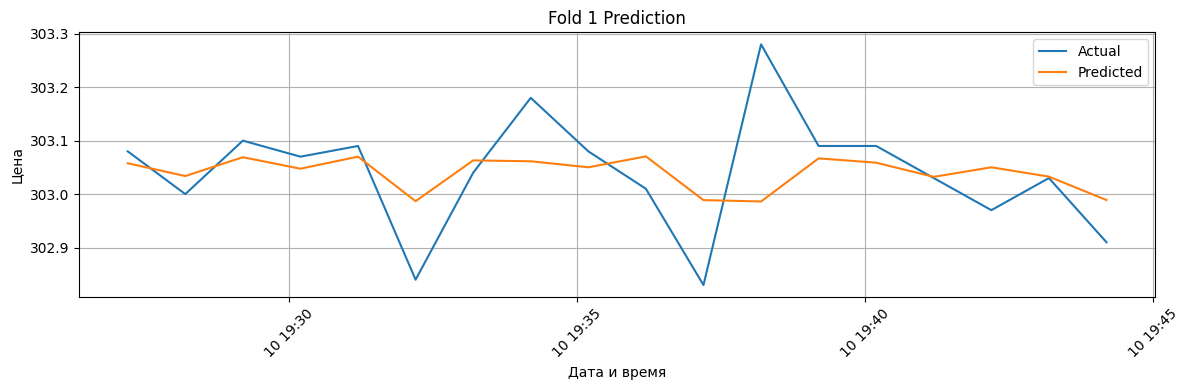

--- Обучение модели fold 2 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step
MSE fold 2: 0.007483

Сравнение фактических и предсказанных значений:
0: Факт = 302.8400, Прогноз = 302.9382
1: Факт = 303.0700, Прогноз = 303.0043
2: Факт = 303.0300, Прогноз = 303.0179
3: Факт = 303.1000, Прогноз = 303.0284
4: Факт = 303.1800, Прогноз = 303.0112
5: Факт = 303.1700, Прогноз = 302.9550
6: Факт = 303.0800, Прогноз = 303.0081
7: Факт = 303.0100, Прогноз = 303.0052
8: Факт = 303.0800, Прогноз = 303.0123
9: Факт = 303.0400, Прогноз = 303.0223
10: Факт = 303.0300, Прогноз = 303.0193
11: Факт = 303.0800, Прогноз = 303.0097
12: Факт = 303.0200, Прогноз = 302.9973
13: Факт = 303.1100, Прогноз = 303.0038
14: Факт = 303.0800, Прогноз = 303.0250
15: Факт = 302.9100, Прогноз = 302.9427
16: Факт = 302.9200, Прогноз = 303.0005
17: Факт = 303.0700, Прогноз = 303.0132


/tmp/ipykernel_1333870/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


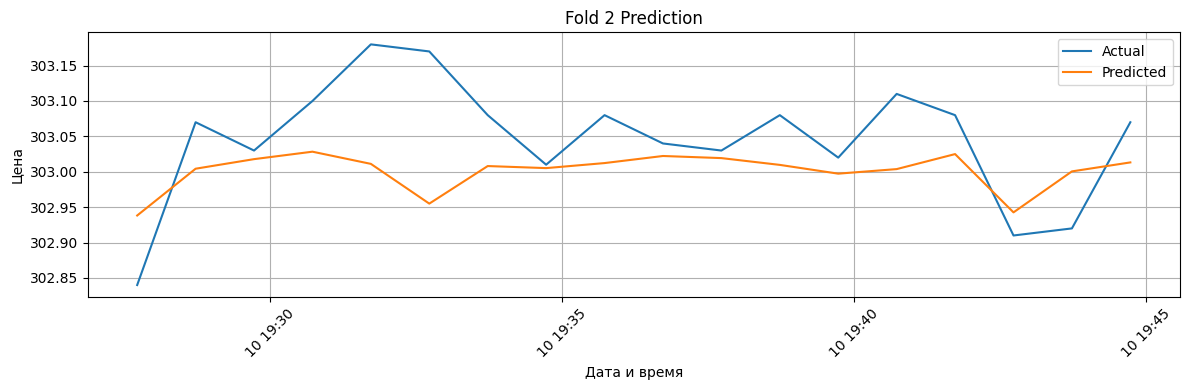

--- Обучение модели fold 3 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step
MSE fold 3: 0.009111

Сравнение фактических и предсказанных значений:
0: Факт = 302.9400, Прогноз = 303.0158
1: Факт = 303.1000, Прогноз = 303.0394
2: Факт = 302.9800, Прогноз = 303.0173
3: Факт = 303.1100, Прогноз = 303.0333
4: Факт = 303.2300, Прогноз = 302.9639
5: Факт = 303.0600, Прогноз = 303.0140
6: Факт = 303.0900, Прогноз = 303.0229
7: Факт = 303.0200, Прогноз = 302.9530
8: Факт = 303.0900, Прогноз = 303.0388
9: Факт = 303.0900, Прогноз = 303.0233
10: Факт = 303.0300, Прогноз = 303.0248
11: Факт = 303.0500, Прогноз = 303.0199
12: Факт = 303.0600, Прогноз = 303.0168
13: Факт = 303.1200, Прогноз = 303.0385
14: Факт = 303.1300, Прогноз = 303.0063
15: Факт = 303.0600, Прогноз = 303.0105
16: Факт = 303.1700, Прогноз = 303.0062
17: Факт = 303.0200, Прогноз = 302.9542


/tmp/ipykernel_1333870/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


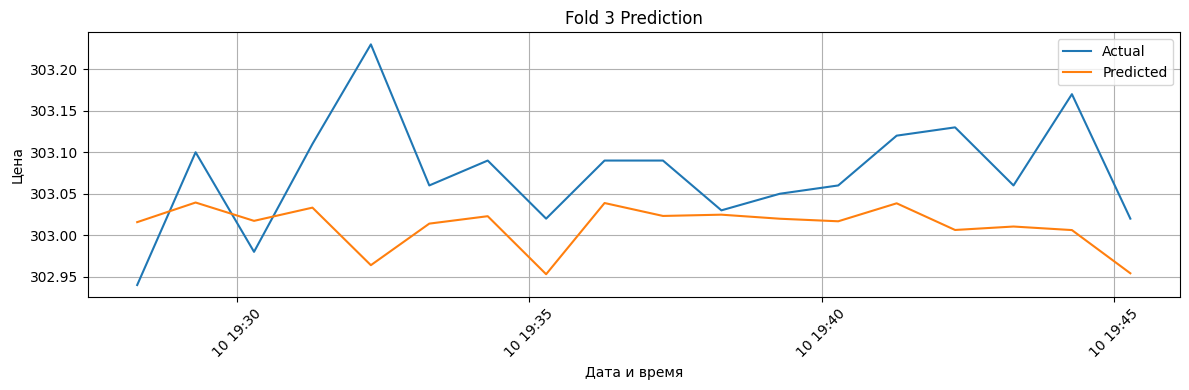

--- Обучение модели fold 4 ---


/home/marcus2tut/.local/lib/python3.11/site-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
MSE fold 4: 0.007187

Сравнение фактических и предсказанных значений:
0: Факт = 303.1300, Прогноз = 303.0652
1: Факт = 303.0300, Прогноз = 303.0580
2: Факт = 302.9900, Прогноз = 303.0545
3: Факт = 302.8300, Прогноз = 303.0117
4: Факт = 302.9100, Прогноз = 303.0101
5: Факт = 303.0400, Прогноз = 303.0514
6: Факт = 303.0600, Прогноз = 303.0414
7: Факт = 302.8600, Прогноз = 303.0115
8: Факт = 302.8900, Прогноз = 303.0094
9: Факт = 303.1000, Прогноз = 303.0519
10: Факт = 303.1400, Прогноз = 303.0657
11: Факт = 302.9400, Прогноз = 303.0730
12: Факт = 303.1000, Прогноз = 303.0951
13: Факт = 303.0900, Прогноз = 303.0746
14: Факт = 303.0800, Прогноз = 303.0704
15: Факт = 303.0000, Прогноз = 303.0561
16: Факт = 303.1400, Прогноз = 303.0494
17: Факт = 303.0200, Прогноз = 303.0677


/tmp/ipykernel_1333870/3561127231.py:30: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  time_indexes = pd.date_range(start=pd.Timestamp.now(), periods=len(preds_inv), freq='T')


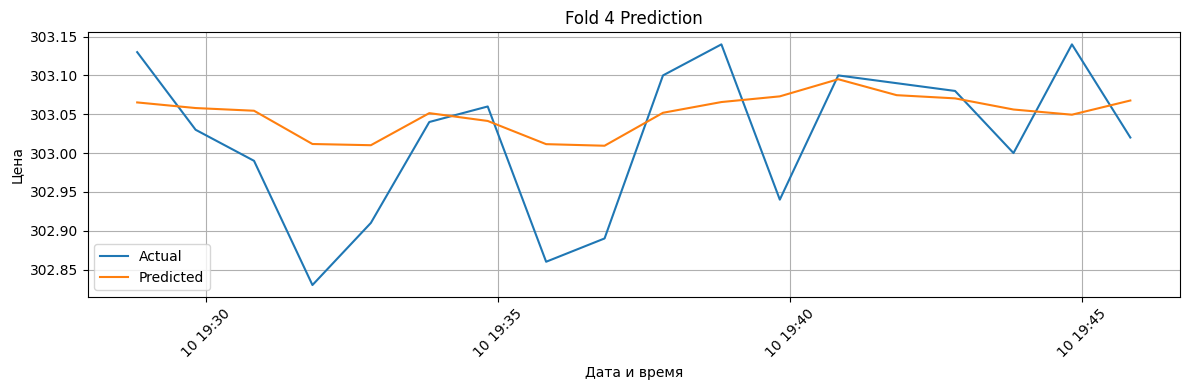


Выбрана лучшая модель с MSE: 0.007187
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Сравнение фактических и предсказанных значений:
                     actual_close  predicted_close
datetime                                          
2025-05-10 16:08:00        303.04       303.090118
2025-05-10 16:09:00        303.09       303.064331
2025-05-10 16:10:00        302.97       303.074402
2025-05-10 16:11:00        302.92       303.065796
2025-05-10 16:12:00        302.85       303.010986
2025-05-10 16:13:00        303.12       303.083221
2025-05-10 16:14:00        303.10       303.091400
2025-05-10 16:15:00        302.99       303.067993
2025-05-10 16:16:00        302.84       303.008179
2025-05-10 16:17:00        303.10       303.084412
2025-05-10 16:18:00        303.17       303.053223
2025-05-10 16:19:00        303.12       303.094177
2025-05-10 16:20:00        303.07       303.073639
2025-05-10 16:21:00        303.06       303.069641
2025-05-10 16:22:00        302.87       303.005890
2025-05-

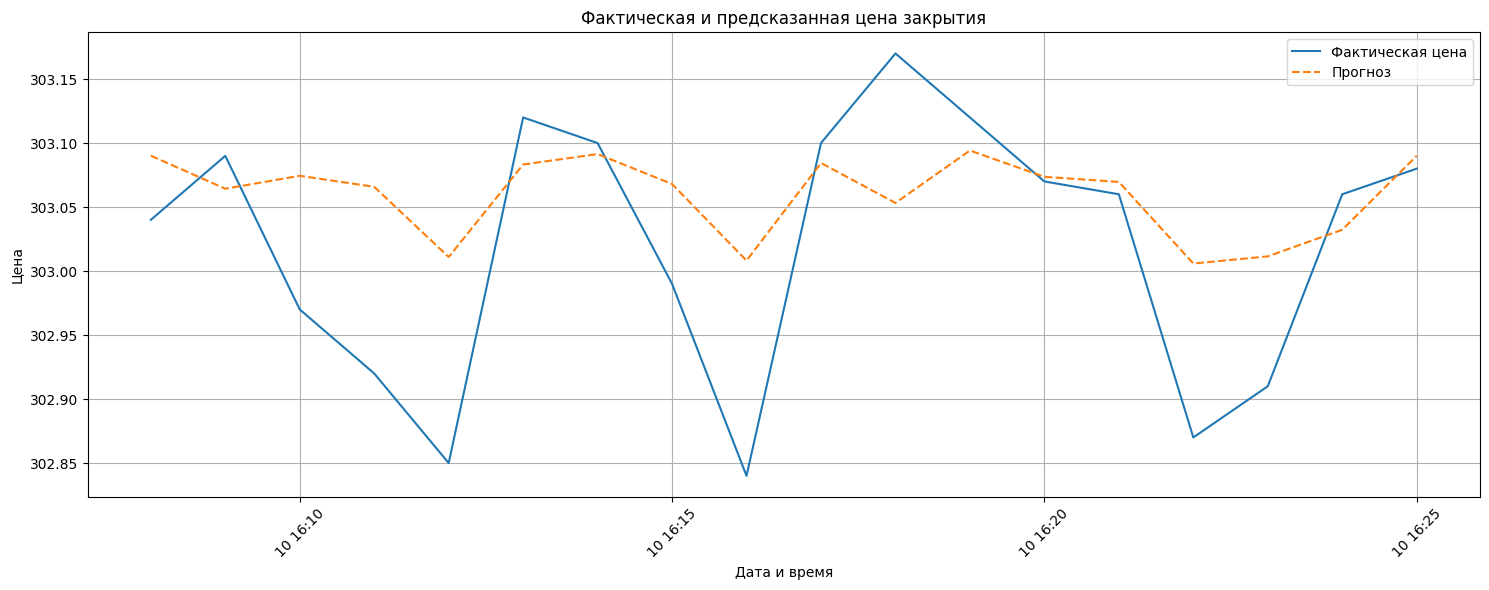


Среднеквадратичная ошибка (MSE): 0.007851


In [18]:
df = get_tinkoff_candles(TINKOFF_API_TOKEN, INSTRUMENT_FIGI, DAYS_HISTORY, CANDLE_TIMEFRAME)
diff_values, original_prices = prepare_data(df, FEATURE_COLUMN)
scaler = MinMaxScaler().fit(diff_values)
scaled = scaler.transform(diff_values)

X_all, y_all = split_sequences(scaled, N_STEPS_IN, N_STEPS_OUT)
X_all = X_all.reshape((X_all.shape[0], X_all.shape[1], 1))

X_trainval, X_test, y_trainval, y_test = train_test_split(X_all, y_all, test_size=0.2, shuffle=True, random_state=42)
best_model = cross_validate_lstm(X_trainval, y_trainval, scaler, n_splits=4)
window_size = 30
final_test(
    best_model,     # обученная модель
    X_test,         # входы тестовой выборки
    y_test,         # правильные ответы (нормализованные)
    scaler,         # объект MinMaxScaler
    df,             # исходный DataFrame с колонками и datetime-индексом
    window_size    # размер скользящего окна, который ты использовал при генерации X
)
